# Demo: generate synthetic 12-lead ECGs with the latent diffusion model (C-M)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shivankmishra144droid/Quality-Aware-Synthetic-Data-Augmentation-for-ECG-Classification/blob/main/report/06_Demo_Generate_ECGs.ipynb)

This notebook loads the final generator from the report (**C-M**: autoencoder + S4 latent diffusion, 5.9 M parameters,
trained for 100k steps on Colab and Kaggle), generates 10-second, 12-lead ECGs for the four rhythm classes, and plots
them next to real PTB-XL ECGs.

- **No dataset download needed.** The checkpoints and 16 real validation ECGs (4 per class) are in the repository.
- **Runtime:** about a minute on a Colab GPU (*Runtime → Change runtime type → T4 GPU*); it also runs on CPU, more slowly.
- **Realism on held-out validation patients** (feature-judge AUC, 0.5 = indistinguishable from real):
  C-M **0.796**, beat stitching 0.965. Details: `report/report.pdf`, Section 8.

## 1. Setup
On Colab this clones the repository; locally it moves to the repository root.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('Quality-Aware-Synthetic-Data-Augmentation-for-ECG-Classification'):
    !git clone --depth 1 https://github.com/shivankmishra144droid/Quality-Aware-Synthetic-Data-Augmentation-for-ECG-Classification.git
if os.path.exists('Quality-Aware-Synthetic-Data-Augmentation-for-ECG-Classification'):
    os.chdir('Quality-Aware-Synthetic-Data-Augmentation-for-ECG-Classification')
elif os.path.basename(os.getcwd()) == 'report':
    os.chdir('..')
sys.path.insert(0, os.getcwd())
print('working directory:', os.path.basename(os.getcwd()))

working directory: ECG-GenAi-submission


In [2]:
import time, logging, warnings
logging.disable(logging.ERROR)      # hide the S4 notices about optional fast kernels (not needed here)
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np
import torch
import matplotlib.pyplot as plt

from latent_diffusion.sample_v2 import Generator, detected_peaks
from latent_diffusion.s4_kernel import conj_kernel
from latent_diffusion.rhythm_v2 import train_peaks
from latent_diffusion.common import ART as V1_ART

CLASSES = ['SR', 'AFIB', 'STACH', 'SBRAD']
NAMES = {'SR': 'sinus rhythm', 'AFIB': 'atrial fibrillation', 'STACH': 'sinus tachycardia', 'SBRAD': 'sinus bradycardia'}
LEADS = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


## 2. Choose what to generate
The model is conditioned on the rhythm class and on heart rate, age and sex. We take these conditions from randomly
chosen training ECGs of each class (only their labels and metadata, which are in the repository).

In [3]:
N_PER_CLASS = 8
y_train = np.load('processed_data/y_train.npy')
fit = np.load(V1_ART / 'partition.npz')['fit']                     # training patients the generator was fitted on
values_all = np.load(V1_ART / 'train_conditions.npz')['values']     # [HR, age, sex] codes + validity flags
_, valid = train_peaks()                                            # rows with a plausible R-peak detection

rng = np.random.default_rng(0)
rows = np.concatenate([rng.choice(fit[(y_train[fit] == c) & valid[fit]], N_PER_CLASS, replace=False) for c in range(4)])
labels, values = y_train[rows], values_all[rows].copy()
print('requested heart rate per class (bpm):')
for c, name in enumerate(CLASSES):
    hr = values[(labels == c) & (values[:, 3] == 1), 0] * 40 + 75   # rows with a recorded heart rate
    print(f'  {name:6s} median {np.median(hr):5.0f}   range {hr.min():.0f}-{hr.max():.0f}')

requested heart rate per class (bpm):
  SR     median    71   range 56-98
  AFIB   median    93   range 66-133
  STACH  median   109   range 103-119
  SBRAD  median    48   range 42-69


## 3. Load C-M and generate
C-M was trained with the conjugate-pair S4 kernel (pykeops on Colab/Kaggle). `conj_kernel()` makes the
plain-PyTorch kernel match it, so sampling gives the same network on any machine. Sampler: classifier-free
guidance 2, 50 DDIM steps (chosen on the development split).

In [4]:
t0 = time.time()
with conj_kernel():
    gen = Generator('cm', device, 'step100000.pt')
    synthetic = gen(labels, values, guidance=2.0, steps=50, seed=0)
print(f'generated {synthetic.shape} (ECGs, samples at 100 Hz, leads) in {time.time() - t0:.0f} s')

real = np.load('report/demo_data/real_val_examples.npz')
X_real, y_real = real['X'], real['y']
print('real validation examples:', X_real.shape)

generated (32, 1000, 12) (ECGs, samples at 100 Hz, leads) in 15 s
real validation examples: (16, 1000, 12)


## 4. Real vs synthetic, lead II
Two real validation ECGs (left, grey) and two synthetic ECGs (right, blue) per class.

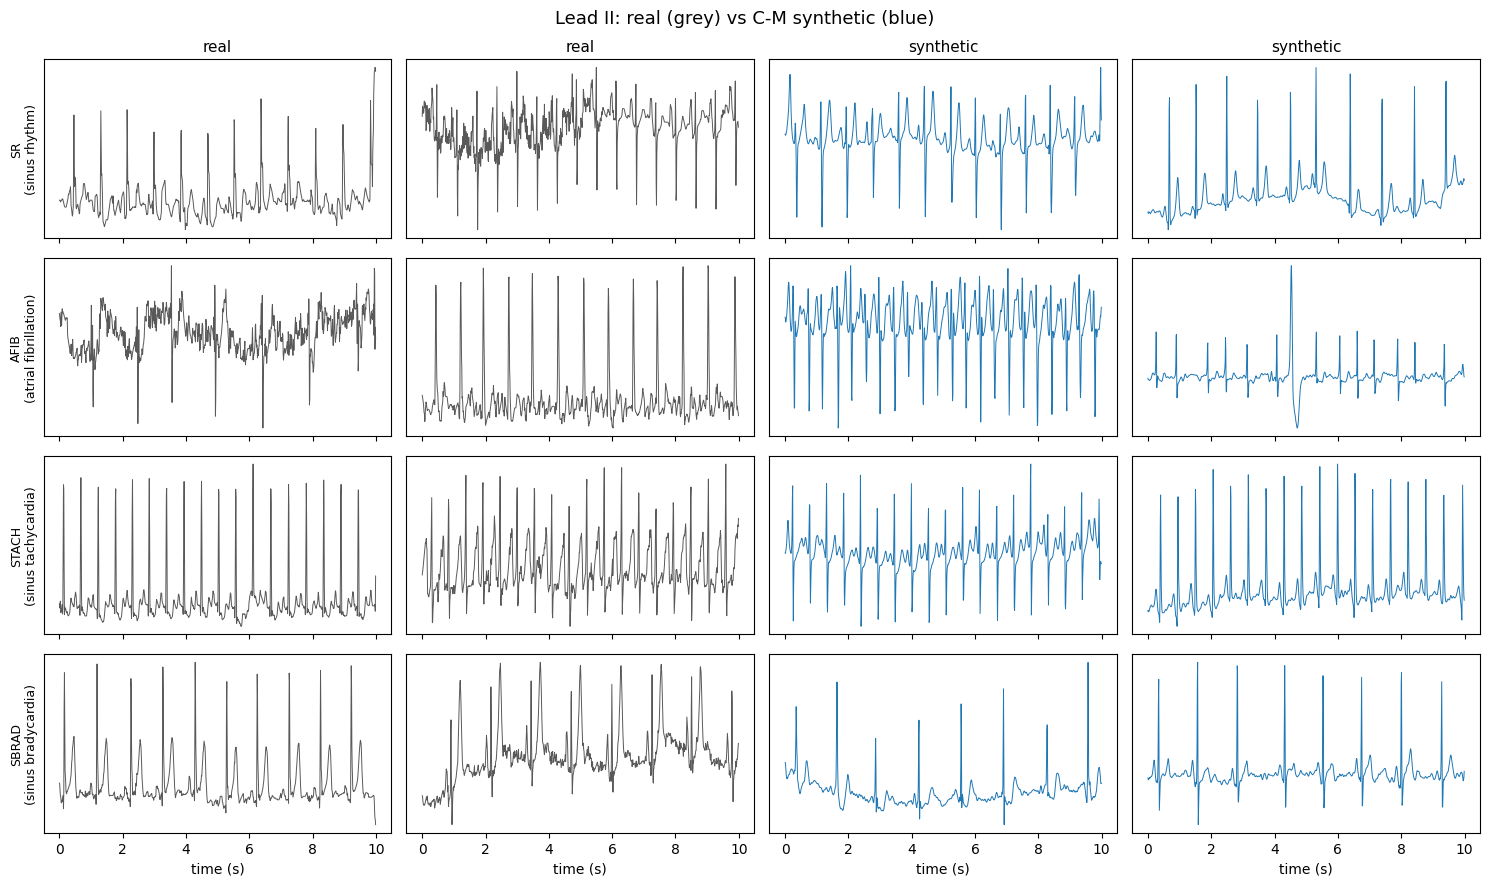

In [5]:
t = np.arange(1000) / 100
fig, axes = plt.subplots(4, 4, figsize=(15, 9), sharex=True)
for c, name in enumerate(CLASSES):
    r = np.flatnonzero(y_real == c)[:2]
    s = np.flatnonzero(labels == c)[:2]
    for j, (X, i, col, kind) in enumerate([(X_real, r[0], '0.35', 'real'), (X_real, r[1], '0.35', 'real'),
                                           (synthetic, s[0], 'tab:blue', 'synthetic'), (synthetic, s[1], 'tab:blue', 'synthetic')]):
        ax = axes[c, j]
        ax.plot(t, X[i, :, 1], lw=0.7, color=col)
        ax.set_yticks([])
        if c == 0:
            ax.set_title(kind, fontsize=11)
        if j == 0:
            ax.set_ylabel(f'{name}\n({NAMES[name]})', fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel('time (s)')
fig.suptitle('Lead II: real (grey) vs C-M synthetic (blue)', fontsize=13)
fig.tight_layout()
plt.show()

## 5. One synthetic ECG, all 12 leads

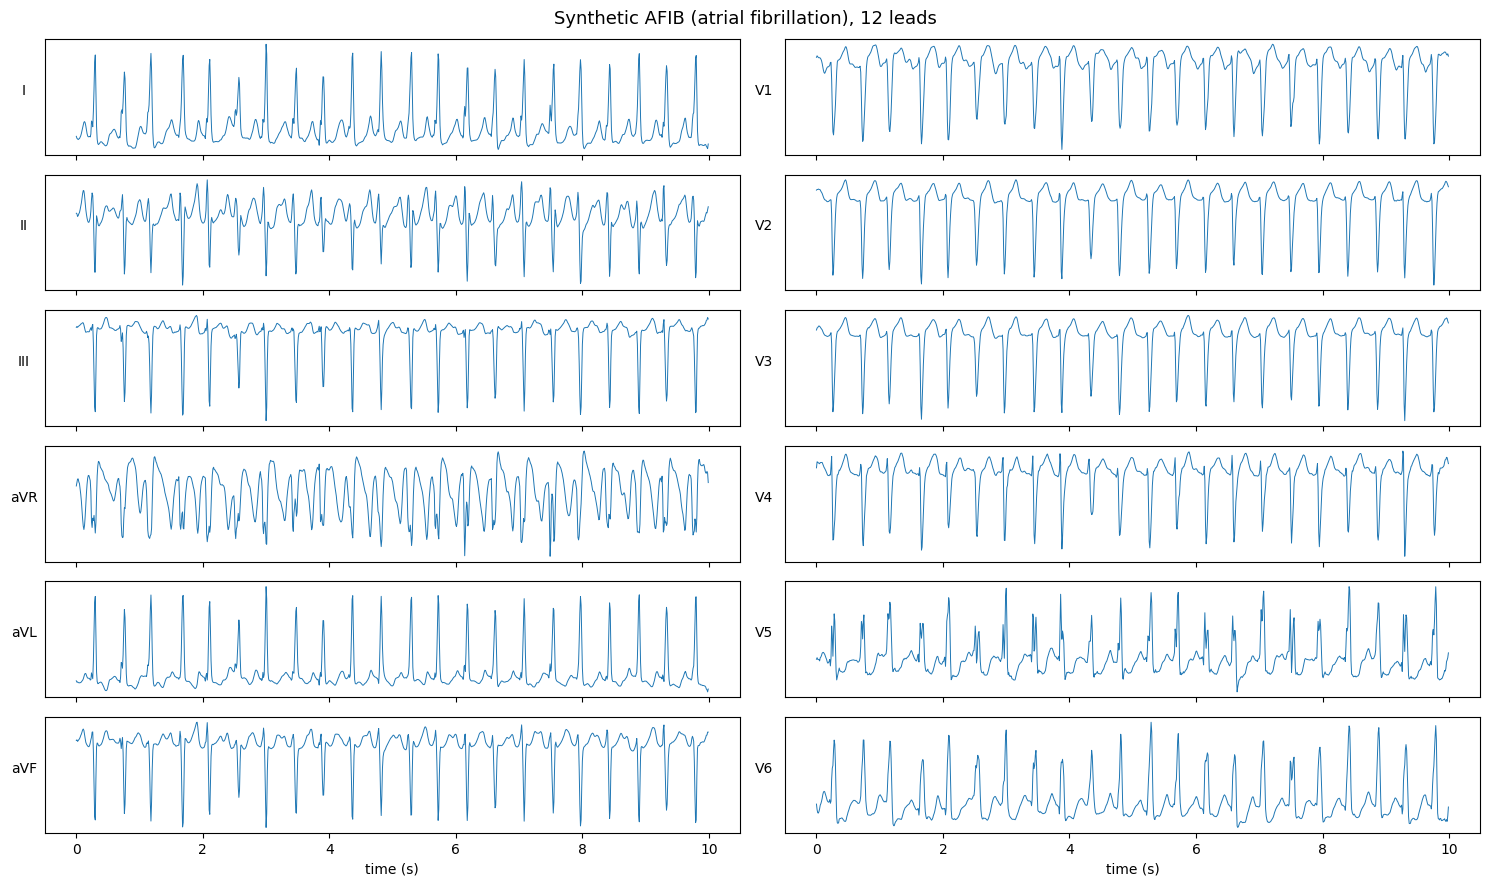

In [6]:
which = 'AFIB'
i = np.flatnonzero(labels == CLASSES.index(which))[0]
fig, axes = plt.subplots(6, 2, figsize=(15, 9), sharex=True)
for k, lead in enumerate(LEADS):
    ax = axes[k % 6, k // 6]
    ax.plot(t, synthetic[i, :, k], lw=0.7, color='tab:blue')
    ax.set_ylabel(lead, rotation=0, labelpad=15)
    ax.set_yticks([])
for ax in axes[-1]:
    ax.set_xlabel('time (s)')
fig.suptitle(f'Synthetic {which} ({NAMES[which]}), 12 leads', fontsize=13)
fig.tight_layout()
plt.show()

## 6. Does the rhythm match the class?
Heart rate measured on the generated ECGs with the project's R-peak detector. Clinically, SBRAD is below 60 bpm,
SR 60-100 bpm and STACH above 100 bpm; AFIB has irregular RR intervals (high RR variability).

In [7]:
def rhythm_stats(X):
    out = []
    for p in detected_peaks(X):
        rr = np.diff(p) / 100
        out.append((60 / rr.mean(), rr.std() / rr.mean()) if len(rr) >= 2 else (np.nan, np.nan))
    return np.array(out)

stats = rhythm_stats(synthetic)
print(f'{"class":6s} {"requested HR":>13s} {"measured HR":>12s} {"RR variability":>15s}')
for c, name in enumerate(CLASSES):
    m = labels == c
    req = np.median(values[m & (values[:, 3] == 1), 0] * 40 + 75)
    print(f'{name:6s} {req:13.0f} {np.nanmedian(stats[m, 0]):12.0f} {np.nanmedian(stats[m, 1]):15.2f}')

class   requested HR  measured HR  RR variability
SR                71           67            0.06
AFIB              93           92            0.24
STACH            109          108            0.03
SBRAD             48           47            0.06


## Notes
- Signals are z-scored per lead with training-split statistics, as in the rest of the project (not millivolts).
- Other checkpoints in `latent_diffusion/artifacts/v2/`: model C (`diffusion_cs/last.pt`) and the R-peak-map model D
  (`diffusion_ds/last.pt`). Both were trained on the laptop, so sample them **without** `conj_kernel()`.
- How realism was measured, and what synthetic data does and does not do for a classifier: `report/report.pdf`.